# FoodLens: cuisine fairness audit

This notebook answers the two questions behind FoodLens's audit:

1. **Is the model less reliable for some cuisines?** Lower accuracy, worse calibration, or different kinds of errors.
2. **Does focal loss reduce those gaps** compared with cross-entropy?

Both models are the same EfficientNet-B0 trained with identical settings; only the loss differs, so differences between them can be attributed to the loss. The notebook reads the test-set prediction files written by `02_models.ipynb` and calls the functions in `src/audit/`, which are tested in `tests/test_audit.py`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(REPO_ROOT))
from src.paths import DATA_DIR, OUTPUTS_DIR
from src import audit

RESULTS_DIR = OUTPUTS_DIR / 'full'
FIG_DIR = RESULTS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

RUN_NAMES = {'Cross-entropy': 'efficientnet_b0_ce', 'Focal loss': 'efficientnet_b0_focal'}
MODELS = {name: RESULTS_DIR / f'predictions_{run}.csv' for name, run in RUN_NAMES.items()}
N_BOOT = 1000
pd.set_option('display.precision', 3)

## Grouping rules

Every result below depends on how dishes are grouped, so the rules are fixed before looking at any accuracy:

- Dishes are grouped by **country or region of origin** into six groups: **Western, East Asian, South Asian, Middle Eastern, Latin American, Other**.
- **Western** = North American, Italian, French and other European dishes (including Spanish paella and British fish and chips).
- **Southeast Asian** dishes (pad thai, pho, spring rolls) count as **East Asian**.
- **Tex-Mex** dishes (nachos, breakfast burrito) count as **Western**; dishes from Mexico or Peru (tacos, ceviche, churros) count as **Latin American**.
- Dishes eaten everywhere with no clear single origin (steak, ice cream, cheesecake, grilled salmon, Caesar salad) go in **Other**.

`cuisine_map.csv` also keeps a finer 10-group `food_group` column (e.g. Italian, French, Southeast Asian) for reference.

## Step 1: Load, join and validate

Each prediction file has one row per test image. Joining it with the cuisine map adds the cuisine of the true dish (`cuisine_group`) and of the predicted dish (`pred_group`). The checks confirm the join lost nothing.

In [2]:
cuisine = audit.load_cuisine_map(DATA_DIR / 'cuisine_map.csv')
frames = {name: audit.load_audit_frame(path, cuisine) for name, path in MODELS.items()}
overall = {name: df['correct'].mean() for name, df in frames.items()}

reported = pd.read_csv(RESULTS_DIR / 'overall_results.csv').set_index('model')['top-1 accuracy']
pd.DataFrame({name: audit.validate_audit_frame(df, expected_accuracy=reported[RUN_NAMES[name]])
              for name, df in frames.items()})

,Cross-entropy,Focal loss
all_labels_mapped,True,True
n_dishes,True,True
images_per_dish,True,True
n_rows,True,True
accuracy_matches_training,True,True


In [3]:
pd.DataFrame({name: {'top-1 accuracy': df['correct'].mean(),
                     'top-5 accuracy': df['top5_correct'].mean(),
                     'mean confidence': df['confidence'].mean()}
              for name, df in frames.items()})

,Cross-entropy,Focal loss
top-1 accuracy,0.844,0.835
top-5 accuracy,0.967,0.967
mean confidence,0.846,0.776


## Step 2: Representation

Every dish has the same number of images (750 train, 250 test), but cuisines have very different numbers of dishes. This imbalance is the starting point of the bias question.

,n_dishes,share_of_classes,n_test_images
cuisine_group,,,
Western,62,0.614,15500
East Asian,16,0.158,4000
Other,12,0.119,3000
Latin American,6,0.059,1500
Middle Eastern,3,0.030,750
South Asian,2,0.020,500


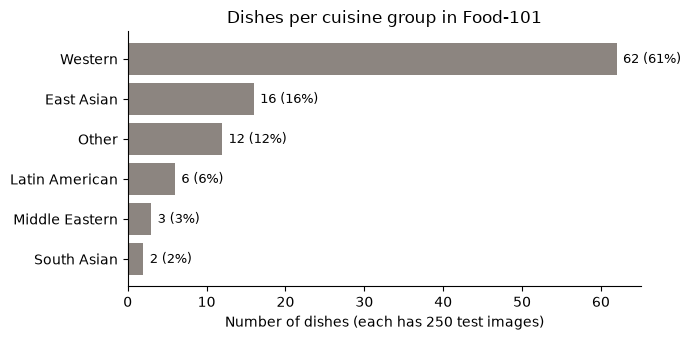

In [4]:
representation = audit.representation_table(cuisine)
fig = audit.plot_representation(representation)
fig.savefig(FIG_DIR / 'audit_1_representation.png', dpi=200)
representation

## Step 3: Performance per cuisine group

Accuracy is the share of a group's test images classified correctly. Precision is computed per dish over the whole test set first and then averaged within each group, because a dish's precision also depends on photos from other cuisines being predicted as it. `gap` is group accuracy minus overall accuracy.

In [5]:
per_dish = {name: audit.per_dish_metrics(df, cuisine) for name, df in frames.items()}
performance = {name: audit.group_performance(frames[name], per_dish[name], n_boot=N_BOOT)
               for name in frames}
performance['Cross-entropy']

,n_images,accuracy,top5_accuracy,precision,recall,f1,ci_low,ci_high,gap,flagged
cuisine_group,,,,,,,,,,
Other,3000,0.767,0.959,0.797,0.767,0.781,0.753,0.783,-7.714e-02,True
South Asian,500,0.802,0.946,0.817,0.802,0.809,0.766,0.836,-4.248e-02,True
Latin American,1500,0.812,0.961,0.819,0.812,0.815,0.791,0.832,-3.248e-02,True
Middle Eastern,750,0.844,0.965,0.842,0.844,0.843,0.819,0.869,-4.752e-04,False
Western,15500,0.849,0.968,0.837,0.849,0.842,0.843,0.854,4.299e-03,False
East Asian,4000,0.903,0.976,0.921,0.903,0.912,0.894,0.912,5.877e-02,False


In [6]:
performance['Focal loss']

,n_images,accuracy,top5_accuracy,precision,recall,f1,ci_low,ci_high,gap,flagged
cuisine_group,,,,,,,,,,
Other,3000,0.780,0.956,0.770,0.780,0.774,0.765,0.795,-5.495e-02,True
South Asian,500,0.786,0.948,0.835,0.786,0.809,0.748,0.820,-4.861e-02,True
Latin American,1500,0.811,0.953,0.819,0.811,0.814,0.790,0.829,-2.395e-02,True
Middle Eastern,750,0.817,0.957,0.844,0.817,0.830,0.792,0.844,-1.728e-02,False
Western,15500,0.835,0.969,0.830,0.835,0.832,0.830,0.841,7.410e-04,False
East Asian,4000,0.891,0.977,0.912,0.891,0.901,0.881,0.901,5.664e-02,False


## Step 4: Is a gap real or just noise?

- **95% intervals** come from resampling each group's test images 1,000 times. Small groups (South Asian has only 2 dishes, 500 images) get wide intervals.
- **Flag rule, fixed in advance:** a group is flagged as *significantly below average* when the upper end of its 95% interval is below the overall accuracy.
- **Dish vs cuisine effect:** the strip plot shows every dish's accuracy. If one hard dish drags a group's average down while the others are fine, that is a dish effect, not a cuisine effect.

,Cross-entropy,Focal loss
cuisine_group,,
Other,True,True
South Asian,True,True
Latin American,True,True
Middle Eastern,False,False
Western,False,False
East Asian,False,False


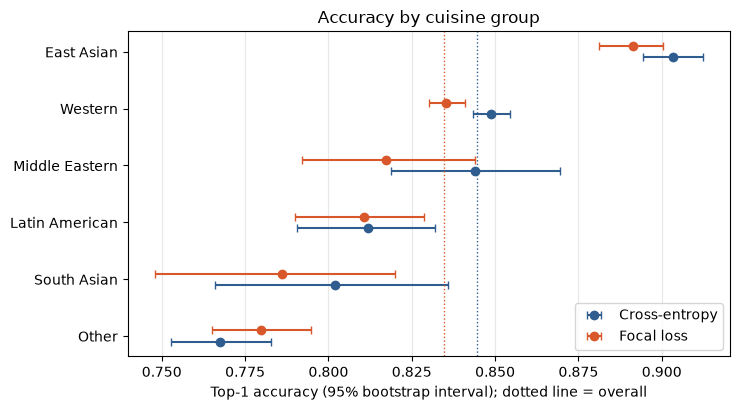

In [7]:
fig = audit.plot_group_accuracy(performance, overall)
fig.savefig(FIG_DIR / 'audit_2_group_accuracy.png', dpi=200)
pd.DataFrame({name: table['flagged'] for name, table in performance.items()})

,label,cuisine_group,accuracy,precision,recall
93,steak,Other,0.464,0.604,0.464
0,apple_pie,Western,0.604,0.729,0.604
77,pork_chop,Other,0.620,0.674,0.620
82,ravioli,Western,0.636,0.776,0.636
39,foie_gras,Western,0.648,0.775,0.648
8,bread_pudding,Western,0.688,0.683,0.688
99,tuna_tartare,Western,0.688,0.775,0.688
15,ceviche,Latin American,0.696,0.770,0.696
56,huevos_rancheros,Latin American,0.716,0.708,0.716
21,chocolate_cake,Other,0.720,0.786,0.720


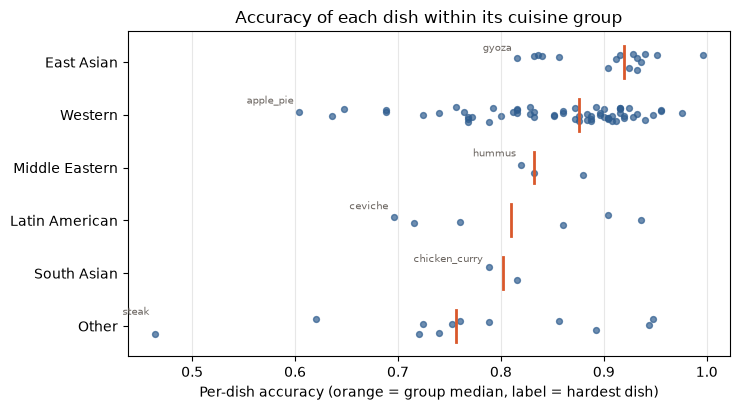

In [8]:
fig = audit.plot_per_dish_spread(per_dish['Cross-entropy'])
fig.savefig(FIG_DIR / 'audit_3_per_dish_spread.png', dpi=200)
per_dish['Cross-entropy'].nsmallest(10, 'accuracy')[['label', 'cuisine_group', 'accuracy', 'precision', 'recall']]

## Step 5: Calibration

A model is calibrated when its confidence matches how often it is right. **Overconfidence** is mean confidence minus accuracy (positive means it claims more certainty than it delivers). **ECE** is the average gap between confidence and accuracy across confidence bins.

For FoodLens, a model that is wrong *and confident* on some cuisines is worse than one that is wrong and unsure, because the app can't warn the user. Focal loss is underconfident overall, so compare its groups with each other and with its overall value rather than with zero.

Cross-entropy                                     Focal loss  \
               mean_confidence accuracy    ece overconfidence mean_confidence   
East Asian               0.904    0.903  0.010      6.608e-04           0.848   
Latin American           0.818    0.812  0.022      5.943e-03           0.751   
Middle Eastern           0.853    0.844  0.029      9.218e-03           0.776   
Other                    0.793    0.767  0.029      2.539e-02           0.722   
South Asian              0.798    0.802  0.030     -3.545e-03           0.737   
Western                  0.845    0.849  0.006     -3.748e-03           0.772   

                                               
               accuracy    ece overconfidence  
East Asian        0.891  0.050         -0.043  
Latin American    0.811  0.060         -0.059  
Middle Eastern    0.817  0.049         -0.041  
Other             0.780  0.058         -0.058  
South Asian       0.786  0.058         -0.049  
Western           0.835  0.063         -0.063

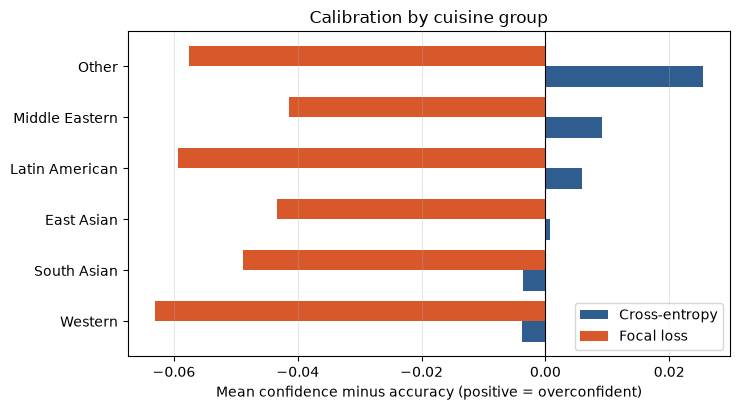

In [9]:
calibration = {name: audit.calibration_by_group(df) for name, df in frames.items()}
fig = audit.plot_calibration(calibration)
fig.savefig(FIG_DIR / 'audit_4_calibration.png', dpi=200)
pd.concat(calibration, axis=1)

## Step 6: Error analysis

For wrong predictions only:
- **within_cuisine:** share of errors predicted as another dish from the same cuisine (a fine-grained mix-up).
- **to_majority:** share of errors predicted as a Western dish. If errors were spread evenly over dishes, this would be close to `majority_class_share`, Western's share of the 101 classes. A clearly higher value means errors are *pulled toward the majority* cuisine.

In [10]:
pd.concat({name: audit.error_breakdown(df) for name, df in frames.items()}, axis=1)

Cross-entropy                                                  \
                    n_errors within_cuisine to_majority majority_class_share   
cuisine_group                                                                  
East Asian               387          0.323       0.416                0.614   
Latin American           282          0.156       0.631                0.614   
Middle Eastern           117          0.009       0.735                0.614   
Other                    698          0.182       0.715                0.614   
South Asian               99          0.000       0.657                0.614   
Western                 2344          0.674       0.674                0.614   

               Focal loss                                                  
                 n_errors within_cuisine to_majority majority_class_share  
cuisine_group                                                              
East Asian            435          0.349       0.400                0.614  
Latin American        284          0.137       0.627                0.614  
Middle Eastern        137          0.007       0.723                0.614  
Other                 661          0.215       0.673                0.614  
South Asian           107          0.009       0.626                0.614  
Western              2552          0.666       0.666                0.614

pred_group,East Asian,Latin American,Middle Eastern,Other,South Asian,Western
cuisine_group,,,,,,
East Asian,0.934,0.006,0.003,0.009,0.008,0.040
Latin American,0.007,0.841,0.010,0.018,0.005,0.119
Middle Eastern,0.012,0.017,0.845,0.007,0.004,0.115
Other,0.011,0.005,0.005,0.810,0.003,0.166
South Asian,0.028,0.014,0.016,0.010,0.802,0.130
Western,0.008,0.011,0.004,0.024,0.003,0.951


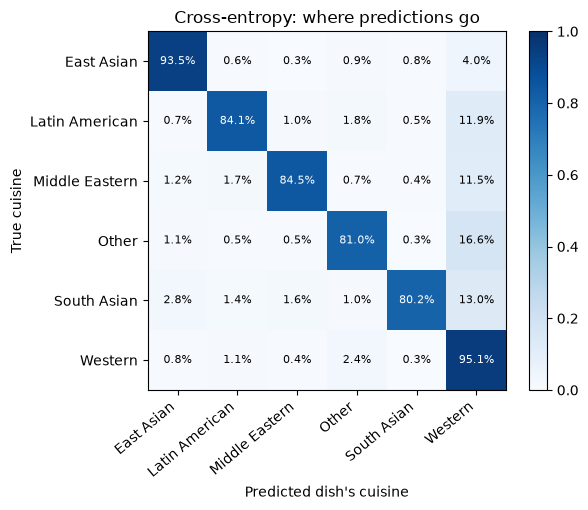

In [11]:
matrix = audit.group_confusion_matrix(frames['Cross-entropy'])
fig = audit.plot_group_confusion(matrix, 'Cross-entropy: where predictions go')
fig.savefig(FIG_DIR / 'audit_5_group_confusion.png', dpi=200)
matrix

In [12]:
audit.most_confused_pairs(frames['Cross-entropy'], per_group=3)

,cuisine_group,label,pred_label,pred_group,count,share_of_dish
0,East Asian,gyoza,dumplings,East Asian,14,0.056
1,East Asian,dumplings,gyoza,East Asian,10,0.040
2,East Asian,ramen,pho,East Asian,9,0.036
3,Latin American,huevos_rancheros,omelette,Western,10,0.040
4,Latin American,huevos_rancheros,nachos,Western,9,0.036
5,Latin American,ceviche,tacos,Latin American,8,0.032
6,Middle Eastern,falafel,crab_cakes,Western,13,0.052
7,Middle Eastern,baklava,apple_pie,Western,6,0.024
8,Middle Eastern,falafel,tacos,Latin American,5,0.020
9,Other,steak,filet_mignon,Western,46,0.184


## Step 7: Cross-entropy vs focal loss

- **Worst-group accuracy:** did the weakest cuisine improve?
- **Max-min gap:** did the spread between groups shrink?
- **Overall accuracy:** did fairness cost overall performance?

The change in gap is tested with a paired bootstrap: both models are scored on the same resampled images, so the interval reflects the difference between the models rather than sampling noise in each one.

In [13]:
comparison = pd.DataFrame({
    'accuracy CE': performance['Cross-entropy']['accuracy'],
    'accuracy focal': performance['Focal loss']['accuracy'],
    'ECE CE': calibration['Cross-entropy']['ece'],
    'ECE focal': calibration['Focal loss']['ece'],
})
comparison.insert(2, 'change', comparison['accuracy focal'] - comparison['accuracy CE'])
comparison.sort_values('accuracy CE')

,accuracy CE,accuracy focal,change,ECE CE,ECE focal
Other,0.767,0.780,0.012,0.029,0.058
South Asian,0.802,0.786,-0.016,0.030,0.058
Latin American,0.812,0.811,-0.001,0.022,0.060
Middle Eastern,0.844,0.817,-0.027,0.029,0.049
Western,0.849,0.835,-0.013,0.006,0.063
East Asian,0.903,0.891,-0.012,0.010,0.050


In [14]:
summary = audit.compare_models(performance, overall)
gap = audit.paired_gap_change(frames['Cross-entropy'], frames['Focal loss'], n_boot=N_BOOT)
print(f"Max-min gap: CE {gap['gap_a']:.3f}, focal {gap['gap_b']:.3f}, "
      f"change {gap['change']:+.3f} (95% CI {gap['change_ci_low']:+.3f} to {gap['change_ci_high']:+.3f})")
summary

Max-min gap: CE 0.136, focal 0.112, change -0.024 (95% CI -0.035 to +0.008)


,overall_accuracy,worst_group,worst_group_accuracy,best_group,max_min_gap,n_flagged
Cross-entropy,0.844,Other,0.767,East Asian,0.136,3
Focal loss,0.835,Other,0.78,East Asian,0.112,3


## Step 8: Reliability file for the app

The app reads this file to show *"Lower reliability for this cuisine"* for flagged groups. `DEPLOYED` must match the model the app uses.

In [15]:
DEPLOYED = 'Focal loss'  # the app bundles the focal loss model (see ios/README.md)
audit.save_cuisine_reliability(performance[DEPLOYED], calibration[DEPLOYED],
                               DATA_DIR / 'cuisine_reliability.csv')

,cuisine_group,accuracy,flagged,ece
0,Other,0.780,True,0.058
1,South Asian,0.786,True,0.058
2,Latin American,0.811,True,0.060
3,Middle Eastern,0.817,False,0.049
4,Western,0.835,False,0.063
5,East Asian,0.891,False,0.050


## Limitations

- **The grouping is a judgment call.** Different rules (e.g. Southeast Asian as its own group) could change the results.
- **Cuisine and visual difficulty are mixed together.** Some groups may contain dishes that simply look alike (soups, curries). The per-dish plot helps separate the two, but cannot fully.
- **Small groups have wide intervals.** South Asian (2 dishes) and Middle Eastern (3) can't support strong conclusions.
- **Food-101's own limits.** A fixed list of 101 dishes from one photo website, with noisy training labels. The results describe this dataset, not all cuisines.